Linear curve fit -> Mean squared error: 3.3750878587, R² score: 0.9335101210
Quadratic curve fit -> Mean squared error: 0.0227617170, R² score: 0.9995515898
Cubic curve fit -> Mean squared error: 0.0227499265, R² score: 0.9995518221
Exponential curve fit -> Mean squared error: 1.1442033420, R² score: 0.9774589744
Logarithmic curve fit -> Mean squared error: 18.0560670129, R² score: 0.6442920121


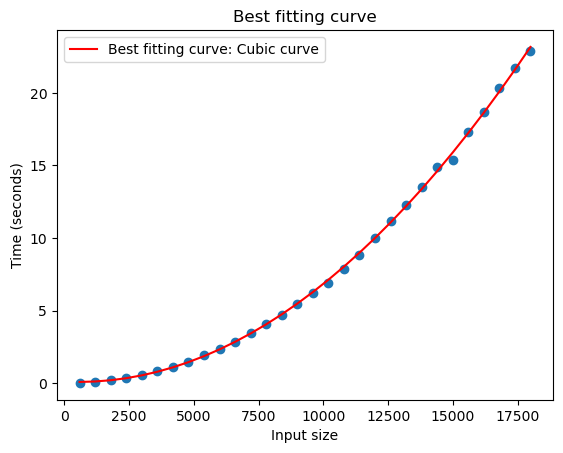

Best fitting curve conclusion: 
The best fitting curve for the data is Cubic curve with a mean squared error of 0.0227499265 and a R² score of 0.9995518221


In [15]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.optimize import curve_fit
from sklearn.metrics import mean_squared_error, r2_score

filePath = 'Dataset_US30.xlsx'
data = pd.read_excel(filePath)

x = data['size'].values
y = data['time'].values

# Functions
def linear(x, a, b):
    return a*x + b

def quadratic(x, a, b, c):
    return a*pow(x,2) + b*x + c

def cubic(x, a, b, c, d):
    return a*pow(x,3) + b*pow(x,2) + c*x + d

def exponential(x, a):
    return pow(a,x)

def logarithmic(x, a, b):
    return a * np.log(x) + b


functions = {"Linear curve": linear, 
             "Quadratic curve": quadratic,
             "Cubic curve": cubic,
             "Exponential curve": exponential,
             "Logarithmic curve": logarithmic}

results = {}

for name, function in functions.items():
    try:
        popt, pcov = curve_fit(function, x, y, maxfev=10000)
        yPred = function(x, *popt)
        meanSquaredError = mean_squared_error(y, yPred)
        r2 = r2_score(y, yPred)
        results[name] = {"params": popt, "mse": meanSquaredError, "r2": r2}
        print(f'{name} fit -> Mean squared error: {meanSquaredError:.10f}, R² score: {r2:.10f}')
    except Exception as e:
        print(f'{name} fit failed: {e}')

bestFittingCurve = min(results, key=lambda k: results[k]["mse"])

popt = results[bestFittingCurve]['params']
yFit = functions[bestFittingCurve](x, *popt)

plt.scatter(x, y)
plt.plot(x, yFit, label=f'Best fitting curve: {bestFittingCurve}', color='red')
plt.legend()
plt.xlabel('Input size')
plt.ylabel('Time (seconds)')
plt.title('Best fitting curve')
plt.show()

meanSquaredError = results[bestFittingCurve]["mse"]
r2 = results[bestFittingCurve]["r2"]
print(f'Best fitting curve conclusion: \nThe best fitting curve for the data is {bestFittingCurve} with a mean squared error of {meanSquaredError:.10f} and a R² score of {r2:.10f}')